# TL6 — Regresión lineal

## Índice

1. [Introducción](#1-introducción)
2. [Regresión lineal](#2-regresión-lineal)
3. [Aplicación a auto-mpg](#3-aplicación-a-auto-mpg)
4. [Ejercicio](#4-ejercicio)

> **Cita:** Juan Ciscar, Alfons. *"Material docente de la asignatura Aprendizaje Automático (APA)"*. Grado de Inteligencia Artificial (GIAR), Escuela Técnica Superior de Ingeniería Informática (ETSINF), Dep. de Sistemas Informáticos y Computación (DSIC), Universitat Politècnica de València (UPV), primer semestre del curso 2026/27.

---
## 1. Introducción

**Regresión lineal:** normal condicional para regresión, $y \in \mathbb{R}$,

$$
p(y \mid \boldsymbol{x}, \boldsymbol{\theta}) = \mathcal{N}(y \mid \mu, \sigma^2)
\quad \text{con} \quad \mu = w_0 + \boldsymbol{w}^t \boldsymbol{x}
$$

**Ingeniería de características:** la entrada $\boldsymbol{x}$ se sustituye por alguna transformación $\boldsymbol{\phi}(\boldsymbol{x})$.

**Objetivo:** aplicar regresión lineal sin y con ingeniería de características.

---
## 2. Regresión lineal

**Regresión lineal:** normal condicional para regresión, $y \in \mathbb{R}$,

$$
p(y \mid \boldsymbol{x}, \boldsymbol{\theta}) = \mathcal{N}(y \mid \mu, \sigma^2)
\quad \text{con} \quad \mu = w_0 + \boldsymbol{w}^t \boldsymbol{x}
$$

**Regresión lineal en scikit-learn:** `LinearRegression`

| Parámetro | Descripción |
|-----------|-------------|
| `fit_intercept=True` | añade $w_0$ |
| `copy_X=True` | copia el dataset de entrenamiento |

### 2.1 Ejemplo

Salida esperada:

```text
1.0
[1. 2.]
3.0000000000000018
[16.]
```

In [52]:
import numpy as np
from sklearn.linear_model import LinearRegression

X = np.array([[1, 1], [1, 2], [2, 2], [2, 3]])
# y = 1 * x_0 + 2 * x_1 + 3
y = np.dot(X, np.array([1, 2])) + 3

reg = LinearRegression().fit(X, y)
print(reg.score(X, y))
print(reg.coef_)
print(reg.intercept_)
print(reg.predict(np.array([[3, 5]])))

1.0
[1. 2.]
3.0000000000000018
[16.]


---
## 3. Aplicación a auto-mpg

**auto-mpg:** predicción de consumo en *miles per gallon*.

### 3.1 Carga del dataset

Salida esperada:

```text
DatasetDict({
    train: Dataset({
        features: ['mpg', 'cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'model year', 'origin', 'car name'],
        num_rows: 398
    })
})
```

In [53]:
import numpy as np
import datasets

ds = datasets.load_dataset("scikit-learn/auto-mpg")
ds

DatasetDict({
    train: Dataset({
        features: ['mpg', 'cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'model year', 'origin', 'car name'],
        num_rows: 398
    })
})

### 3.2 Formato: conversión a *dataframe* de pandas

Salida esperada:

```text
<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64
 2   displacement  398 non-null    float64
 3   horsepower    398 non-null    str
 4   weight        398 non-null    int64
 5   acceleration  398 non-null    float64
 6   model year    398 non-null    int64
 7   origin        398 non-null    int64
 8   car name      398 non-null    str
dtypes: float64(3), int64(4), str(2)
memory usage: 35.3 KB
```

In [54]:
import pandas as pd

df = ds['train'].to_pandas()
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    398 non-null    str    
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model year    398 non-null    int64  
 7   origin        398 non-null    int64  
 8   car name      398 non-null    str    
dtypes: float64(3), int64(4), str(2)
memory usage: 35.3 KB


### 3.3 Preproceso

Tras examinar variables en el *Dataset Viewer*:

- `horsepower`: normalización de tipo tras eliminar seis casos con `"?"`.
- `origin`: normalización de tipo ya que es una categórica con tres posibles valores; 1, 2 o 3.
- `car name`: eliminación ya que el modelo de coche no interesa como variable explicativa.

Salida esperada:

```text
<class 'pandas.DataFrame'>
Index: 392 entries, 0 to 397
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   mpg           392 non-null    float64
 1   cylinders     392 non-null    int64
 2   displacement  392 non-null    float64
 3   horsepower    392 non-null    int64
 4   weight        392 non-null    int64
 5   acceleration  392 non-null    float64
 6   model year    392 non-null    int64
 7   origin        392 non-null    category
dtypes: category(1), float64(3), int64(4)
memory usage: 24.9 KB
```

In [55]:
df.drop(df[df.horsepower == "?"].index, inplace=True)
df = df.astype({'horsepower' : np.int64})
df['origin'] = df['origin'].map({1: 'USA', 2: 'Europe', 3: 'Japan'})
df = df.astype({'origin' : 'category'})
df.drop('car name', axis=1, inplace=True)
df.info()

<class 'pandas.DataFrame'>
Index: 392 entries, 0 to 397
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype   
---  ------        --------------  -----   
 0   mpg           392 non-null    float64 
 1   cylinders     392 non-null    int64   
 2   displacement  392 non-null    float64 
 3   horsepower    392 non-null    int64   
 4   weight        392 non-null    int64   
 5   acceleration  392 non-null    float64 
 6   model year    392 non-null    int64   
 7   origin        392 non-null    category
dtypes: category(1), float64(3), int64(4)
memory usage: 24.9 KB


### 3.4 Inspección visual

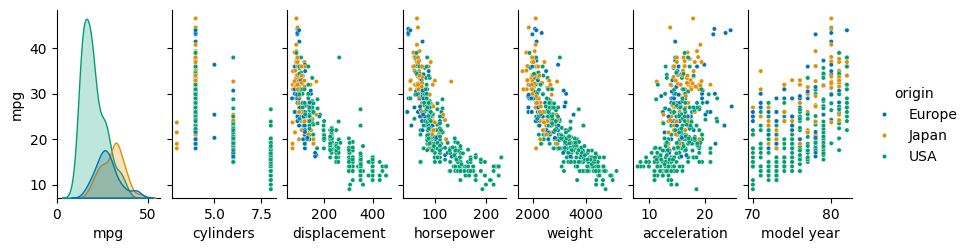

In [56]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.pairplot(df, y_vars='mpg', hue="origin", aspect=.5, palette='colorblind', plot_kws=dict(marker="o", s=10))
plt.show()

### 3.5 Diseño experimental

- Binarización de `origin` para facilitar su tratamiento.
- Partición de los datos en entrenamiento y test.
- Estandarización de características.

In [57]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

df = pd.concat([df, pd.get_dummies(df.origin, prefix='', prefix_sep='')], axis=1)
df.drop('origin', axis=1, inplace=True)
y = df.pop('mpg')
X = df

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

### 3.6 Regresión lineal sin ingeniería de características

In [58]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

linreg = LinearRegression().fit(X_train, y_train)
y_train_pred = linreg.predict(X_train)
y_test_pred = linreg.predict(X_test)
r2_train = r2_score(y_train, y_train_pred)
r2_test = r2_score(y_test, y_test_pred)

Valores reales frente a predichos en *train* (izquierda) y *test* (derecha):

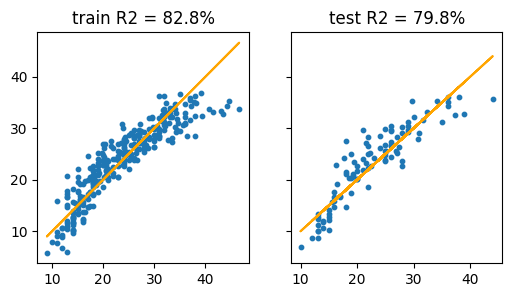

In [59]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(1, 2, figsize=(6, 3), sharey='all')

ax = axs[0]
ax.set_title(f'train R2 = {r2_train:.1%}')
ax.scatter(y_train, y_train_pred, s=10)
ax.plot(y_train, y_train, color='orange')

ax = axs[1]
ax.set_title(f'test R2 = {r2_test:.1%}')
ax.scatter(y_test, y_test_pred, s=10)
ax.plot(y_test, y_test, color='orange')

plt.show()

### 3.7 Regresión lineal con ingeniería de características

Características polinómicas de grado 2.

In [60]:
from sklearn.preprocessing import PolynomialFeatures

poly = PolynomialFeatures(2)
X_train = poly.fit_transform(X_train)
X_test = poly.transform(X_test)

linreg = LinearRegression().fit(X_train, y_train)
y_train_pred = linreg.predict(X_train)
y_test_pred = linreg.predict(X_test)
r2_train = r2_score(y_train, y_train_pred)
r2_test = r2_score(y_test, y_test_pred)

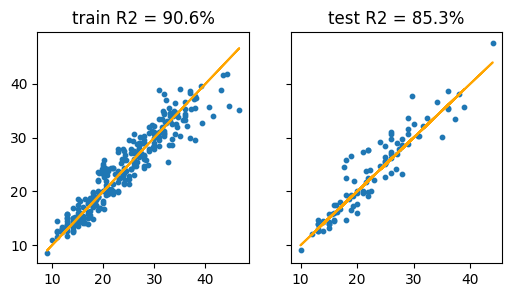

In [61]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(1, 2, figsize=(6, 3), sharey='all')

ax = axs[0]
ax.set_title(f'train R2 = {r2_train:.1%}')
ax.scatter(y_train, y_train_pred, s=10)
ax.plot(y_train, y_train, color='orange')

ax = axs[1]
ax.set_title(f'test R2 = {r2_test:.1%}')
ax.scatter(y_test, y_test_pred, s=10)
ax.plot(y_test, y_test, color='orange')

plt.show()

---
## 4. Ejercicio

**Ejercicio:** aplica regresión lineal sin y con ingeniería de características a los datasets siguientes:

- [`scikit-learn/Fish`](https://huggingface.co/datasets/scikit-learn/Fish) para predecir el peso de un pez a partir de sus medidas.
- [California housing](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.fetch_california_housing.html) para predecir el valor de una casa californiana.

**Aplicación a Fish:** $R^2$ (%) en test: sin 94.8, con 96.2

**Aplicación a California housing:** $R^2$ (%) en test: sin 59.1, con 65.6

### 4.1 Aplicación a Fish

#### 4.1.1 Carga del dataset

Salida esperada:

```text
<class 'pandas.DataFrame'>
RangeIndex: 159 entries, 0 to 158
Data columns (total 7 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   Species  159 non-null    str
 1   Weight   159 non-null    float64
 2   Length1  159 non-null    float64
 3   Length2  159 non-null    float64
 4   Length3  159 non-null    float64
 5   Height   159 non-null    float64
 6   Width    159 non-null    float64
dtypes: float64(6), str(1)
memory usage: 9.6 KB
```

In [62]:
import numpy as np
import datasets

ds = datasets.load_dataset("scikit-learn/fish")

df = ds['train'].to_pandas()
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 159 entries, 0 to 158
Data columns (total 7 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Species  159 non-null    str    
 1   Weight   159 non-null    float64
 2   Length1  159 non-null    float64
 3   Length2  159 non-null    float64
 4   Length3  159 non-null    float64
 5   Height   159 non-null    float64
 6   Width    159 non-null    float64
dtypes: float64(6), str(1)
memory usage: 9.6 KB


['Species', 'Weight', 'Length1', 'Length2', 'Length3', 'Height', 'Width']


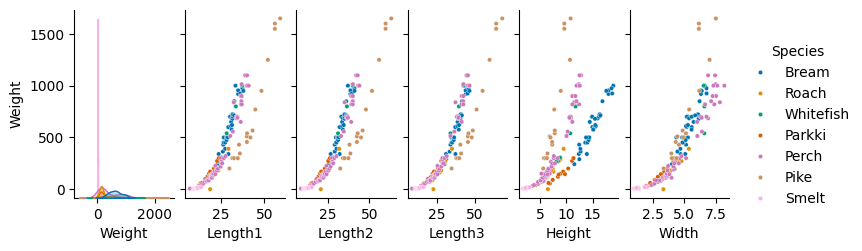

In [63]:
import seaborn as sns
print(df.columns.tolist())
sns.pairplot(df, y_vars='Weight', hue="Species", aspect=.5, palette='colorblind', plot_kws=dict(marker="o", s=10));

#### 4.1.2 Preproceso y diseño experimental

Binarización de `Species`, partición en entrenamiento y test, y estandarización.

In [64]:

df = df.astype({'Species' : 'category'})
df = pd.concat([df, pd.get_dummies(df.Species, prefix='', prefix_sep='')], axis=1)
df.drop('Species', axis=1, inplace=True); y = df.pop('Weight');
X = df
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

#### 4.1.3 Regresión lineal sin ingeniería de características

R2 train: 92.9%, R2 test: 94.8%


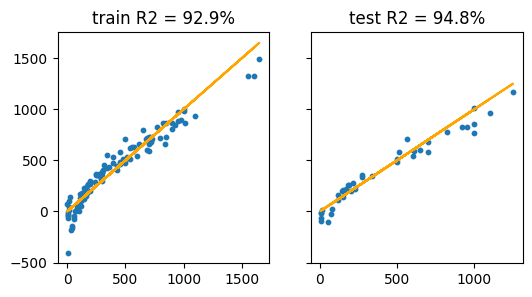

In [65]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
import matplotlib.pyplot as plt

linreg = LinearRegression()
linreg.fit(X_train, y_train)
y_train_pred = linreg.predict(X_train)
y_test_pred = linreg.predict(X_test)

r2_train = r2_score(y_train, y_train_pred)
r2_test = r2_score(y_test, y_test_pred)


fig, axs = plt.subplots(1, 2, figsize=(6, 3), sharey = 'all')
ax = axs[0]; ax.set_title(f'train R2 = {r2_train:.1%}')
ax.scatter(y_train, y_train_pred, s=10); ax.plot(y_train, y_train, color='orange')
ax = axs[1]; ax.set_title(f'test R2 = {r2_test:.1%}')
ax.scatter(y_test, y_test_pred, s=10); ax.plot(y_test, y_test, color='orange')

print(f'R2 train: {r2_train:.1%}, R2 test: {r2_test:.1%}')

#### 4.1.4 Regresión lineal con ingeniería de características

Salida esperada: `R2: sin 94.8% con 96.2% (train: sin 92.9% con 99.1%)`

R2 train: 99.1%, R2 test: 96.2%


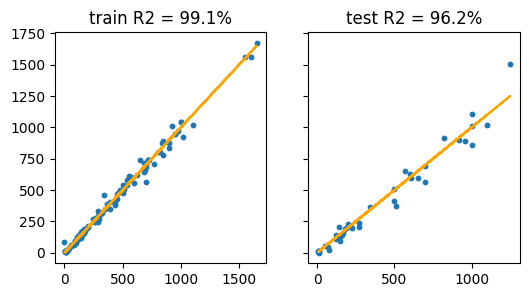

In [66]:
poly = PolynomialFeatures(2)
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)
linreg_poly = LinearRegression().fit(X_train_poly, y_train)
y_train_pred = linreg_poly.predict(X_train_poly)
y_test_pred = linreg_poly.predict(X_test_poly)
r2_train = r2_score(y_train, y_train_pred)
r2_test = r2_score(y_test, y_test_pred)

print(f'R2 train: {r2_train:.1%}, R2 test: {r2_test:.1%}')

fig, axs = plt.subplots(1, 2, figsize=(6, 3), sharey="all")
ax = axs[0]
ax.set_title(f"train R2 = {r2_train:.1%}")
ax.scatter(y_train, y_train_pred, s=10)
ax.plot(y_train, y_train, color="orange")


ax = axs[1]
ax.set_title(f"test R2 = {r2_test:.1%}")
ax.scatter(y_test, y_test_pred, s=10)
ax.plot(y_test, y_test, color="orange") 

plt.show()


### 4.2 Aplicación a California housing

#### 4.2.1 Carga, partición y estandarización

Salida esperada:

```text
(20640, 8) (20640,)
[[ 8.3252e+00  4.1000e+01  6.9841e+00  1.0238e+00  3.2200e+02  2.5556e+00
   3.7880e+01 -1.2223e+02  4.5260e+00]
 [ 8.3014e+00  2.1000e+01  6.2381e+00  9.7190e-01  2.4010e+03  2.1098e+00
   3.7860e+01 -1.2222e+02  3.5850e+00]
 [ 7.2574e+00  5.2000e+01  8.2881e+00  1.0734e+00  4.9600e+02  2.8023e+00
   3.7850e+01 -1.2224e+02  3.5210e+00]]
```

In [67]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X, y = fetch_california_housing(return_X_y=True) 
print(X.shape, y.shape)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
print(np.round(np.c_[(X, y)][:3,:], 4))

(20640, 8) (20640,)
[[ 8.3252e+00  4.1000e+01  6.9841e+00  1.0238e+00  3.2200e+02  2.5556e+00
   3.7880e+01 -1.2223e+02  4.5260e+00]
 [ 8.3014e+00  2.1000e+01  6.2381e+00  9.7190e-01  2.4010e+03  2.1098e+00
   3.7860e+01 -1.2222e+02  3.5850e+00]
 [ 7.2574e+00  5.2000e+01  8.2881e+00  1.0734e+00  4.9600e+02  2.8023e+00
   3.7850e+01 -1.2224e+02  3.5210e+00]]


#### 4.2.2 Regresión lineal sin ingeniería de características

R2 train: 61.0%, R2 test: 59.1%


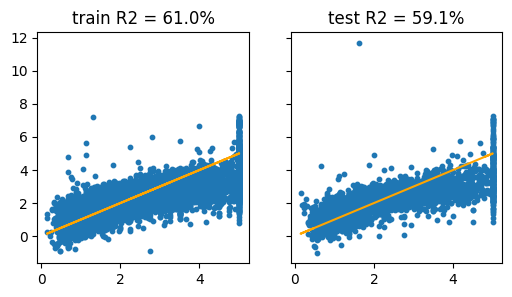

In [68]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
import matplotlib.pyplot as plt

linreg = LinearRegression()
linreg.fit(X_train, y_train)
y_train_pred = linreg.predict(X_train)
y_test_pred = linreg.predict(X_test)

r2_train = r2_score(y_train, y_train_pred)
r2_test = r2_score(y_test, y_test_pred)


fig, axs = plt.subplots(1, 2, figsize=(6, 3), sharey = 'all')
ax = axs[0]; ax.set_title(f'train R2 = {r2_train:.1%}')
ax.scatter(y_train, y_train_pred, s=10); ax.plot(y_train, y_train, color='orange')
ax = axs[1]; ax.set_title(f'test R2 = {r2_test:.1%}')
ax.scatter(y_test, y_test_pred, s=10); ax.plot(y_test, y_test, color='orange')

print(f'R2 train: {r2_train:.1%}, R2 test: {r2_test:.1%}')

#### 4.2.3 Regresión lineal con ingeniería de características

Salida esperada: `R2: sin 59.1% con 65.6% (train: sin 61.0% con 68.3%)`

R2 train: 68.3%, R2 test: 65.6%


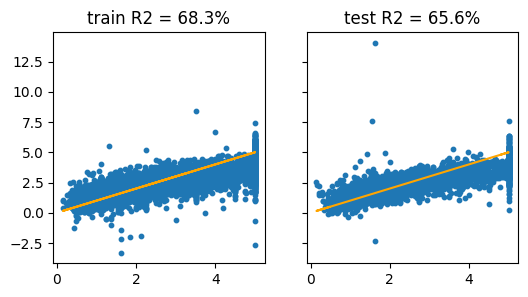

In [70]:
from sklearn.preprocessing import PolynomialFeatures
poly = PolynomialFeatures(2)
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)
linreg_poly = LinearRegression().fit(X_train_poly, y_train)

y_train_pred = linreg_poly.predict(X_train_poly)
y_test_pred = linreg_poly.predict(X_test_poly)

r2_train = r2_score(y_train, y_train_pred)
r2_test = r2_score(y_test, y_test_pred)
fig, axs = plt.subplots(1, 2, figsize=(6, 3), sharey="all")
print(f'R2 train: {r2_train:.1%}, R2 test: {r2_test:.1%}')

ax = axs[0]
ax.set_title(f"train R2 = {r2_train:.1%}")
ax.scatter(y_train, y_train_pred, s=10)
ax.plot(y_train, y_train, color="orange")

ax = axs[1]
ax.set_title(f"test R2 = {r2_test:.1%}")
ax.scatter(y_test, y_test_pred, s=10)
ax.plot(y_test, y_test, color="orange") 

plt.show() 